In [7]:
import copy
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
import torchvision
import torch.optim as optim
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [8]:
def split_dataset():
  #resize to 224 × 224 for standard input
  transform = transforms.Compose([
      transforms.Resize((224, 224)),
      transforms.ToTensor(),
      transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225])
  ])

  #retrive full dataset
  train_ds_full = datasets.OxfordIIITPet("./data", split="trainval", target_types="category",
                                          transform=transform, download=True)
  eval_ds_full = datasets.OxfordIIITPet("./data", split="trainval", target_types="category",
                                          transform=transform, download=True)
  test_ds = datasets.OxfordIIITPet("./data", split="test", target_types="category",
                                          transform=transform, download=True)
  # one breed label per image
  labels = train_ds_full._labels

  # Stratified split by breed, each breed keep the same rateo on the two split
  train_idx, val_idx = train_test_split(
      range(len(labels)),
      test_size=0.2,
      stratify=labels,
      random_state=42,
  )

  # 80/20 ds_full splitted
  ds_train = Subset(train_ds_full, train_idx)
  ds_eval = Subset(eval_ds_full, val_idx)

  return ds_train, ds_eval, test_ds



In [9]:
#train and validation
def epochTrain(model, train_loader, criterion, optimizer):
  model.train()
  n = 0
  tot_loss = 0.0
  tot_acc = 0.0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    preds = (outputs.argmax(dim=1) == labels).sum().item()

    tot_loss += loss.item() * images.size(0)
    tot_acc += preds
    n += images.size(0)

  return tot_acc / n, tot_loss / n

def epochVal(model, val_loader, criterion):
  with torch.no_grad():
    model.eval()
    n = 0
    tot_loss = 0.0
    tot_acc = 0.0

    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      preds = (outputs.argmax(dim=1) == labels).sum().item()


      tot_loss += loss.item() * images.size(0)
      tot_acc += preds
      n += images.size(0)

  return tot_acc / n, tot_loss / n

In [24]:
#training on all the epochs
def running_epoch(model, train_loader, eval_loader, criterion, optimizer):

  f_best_acc = 0
  p_best_acc = 0
  epochs = 12

  f_epoch_pass = 0
  for epoch in range(epochs):
    f_t_acc, f_t_loss = epochTrain(model, train_loader, criterion, optimizer)
    f_v_acc, f_v_loss = epochVal(model, eval_loader, criterion)

    f_epoch_pass += 1
    if(f_epoch_pass == epochs/4):
      print(f"other {epochs/4} epochs achieved!")
      print(f"train loss {f_t_loss:.3f} train acc {f_t_acc:.3f}\nval loss {f_v_loss:.3f} val acc {f_v_acc:.3f}\n\n\n")
      f_epoch_pass = 0

    if f_v_acc > f_best_acc:
            best_epoch, f_best_acc, f_best_state = epoch, f_v_acc, copy.deepcopy(model.state_dict())

  return best_epoch, f_best_state


In [11]:
#function to plot confusion matrix
def plotCm(cm,test_ds):
  class_names = test_ds.classes
  cm_norm = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1 (per-breed recall)

  fig, ax = plt.subplots(figsize=(14, 12))
  im = ax.imshow(cm_norm, cmap="Blues")
  ax.set_xticks(range(37)); ax.set_yticks(range(37))
  #ax.set_xticklabels(class_names, rotation=90, fontsize=7)
  #ax.set_yticklabels(class_names, fontsize=7)
  ax.set_xlabel("Predicted breed"); ax.set_ylabel("True breed")
  ax.set_title("Confusion matrix (normalized by true class)")
  fig.colorbar(im)
  plt.tight_layout()
  plt.show()

In [12]:
def show_val(acc, cm, macro_f1):
    print(f"Test Set Accuracy: {acc:.2f}%")
    print(f"Test Set Macro F1 score: {macro_f1:.2f}")
    plotCm(cm, test_ds)

In [13]:
#final test

def test_model(model, test_loader):
  model.eval()
  correct = 0
  tot = 0

  with torch.no_grad():
    all_preds, all_labels = [], []
    for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)

      #total accuracy
      _, pred = torch.max(outputs, 1)
      tot += labels.size(0)
      correct += (pred == labels).sum().item()

      #f1-score
      all_preds.append(outputs.argmax(dim=1).cpu())
      all_labels.append(labels.cpu())


    acc = 100.0 * correct/tot
    x_true = torch.cat(all_labels).numpy()
    y_pred = torch.cat(all_preds).numpy()
    macro_f1 = f1_score(x_true, y_pred, average="macro")
    #print(classification_report(x_true, y_pred, target_names=test_ds.classes))
    cm = confusion_matrix(x_true, y_pred, labels=range(37))

    show_val(acc, cm, macro_f1)

In [14]:
#TRAIN&TEST OF THE ENTIRE NETWORK
def train_test_net(model_ft, train_loader, eval_loader, test_loader, criterion, optimizer):
  print("TRAIN OF THE FULL NETWORK")
  f_epoch, f_best_state = running_epoch(model_ft, train_loader, eval_loader, criterion, optimizer)

  model_ft.load_state_dict(f_best_state)           # restore best epoch


  print("TEST OF THE FULL FINE TUNING")
  test_model(model_ft,test_loader)

In [22]:
#TRAIN&TEST ONLY OF THE FULLY CONNECTED LAYERS
def train_test_oc(model_oc, train_loader, eval_loader, test_loader, criterion):
  #freeze all
  for param in model_oc.parameters():
      param.requires_grad = False

  #unfreeze the fully connected layer
  for param in model_oc.classifier[3].parameters(): #only the last layer to reduce overfitting
      param.requires_grad = True

  optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model_oc.parameters()), lr=1e-4) #1e-3 overfit

  print("TRAIN OF ONLY THE FULLY CONNECTED LAYERS")
  c_epoch, c_best_state = running_epoch(model_oc, train_loader, eval_loader, criterion, optimizer)

  model_oc.load_state_dict(c_best_state)

  print("\n\n\nTEST OF THE ONLY CONVOLUTIONAL LAYER TRAINING")
  test_model(model_oc,test_loader)


In [16]:
def extract(dataset, prenet):
    loader = DataLoader(dataset, batch_size=64, shuffle=False)
    x, y = [], []
    for images, labels in loader:
        x.append(prenet(images.to(device)).cpu())
        y.append(labels)
    return torch.cat(x).numpy(), torch.cat(y).numpy()

In [17]:
def feat_extr_tc(prenet, ds_train, ds_val, ds_test):
  prenet = prenet.to(device).eval()
  for p in prenet.parameters():
      p.requires_grad = False

  with torch.no_grad():
    x_train, y_train = extract(ds_train, prenet)
    x_val,   y_val   = extract(ds_val, prenet)
    x_test,  y_test  = extract(ds_test, prenet)

    configs = [(n, d) for n in [100, 300, 500] for d in [None, 20]] #random forest hyperparam
    best_acc, best_cfg, best_rf = -1, None, None

    for n, d in configs:
      rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=0, n_jobs=-1)
      rf.fit(x_train, y_train)
      acc = accuracy_score(y_val, rf.predict(x_val))
      if acc > best_acc:
          best_acc, best_cfg, best_rf = acc, (n, d), rf


  pred = best_rf.predict(x_test)
  print(f"test acc {accuracy_score(y_test, pred):.4f} | macro F1 {f1_score(y_test, pred, average='macro'):.4f}")

  cm = confusion_matrix(y_test, pred, labels=range(37))
  plotCm(cm, ds_test)

In [18]:
#INITIALIZATION OF DATASET AND MODEL
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}\n")


ds_train, ds_eval, test_ds = split_dataset()


#load subset of full ds for trainval split
train_loader = DataLoader(ds_train, batch_size=32, shuffle=True)
eval_loader = DataLoader(ds_eval, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False) #use only for final valutation


model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT).to(device)
prenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)


#change the output layer from default (1024) to our case (37)
model.classifier[3] = nn.Linear(1024, 37)
prenet.classifier = nn.Identity()

#create two model to have two best state different from fine tuning and only conv train
model_ft = model.to(device)
model_oc = model.to(device)

Using device: cpu



TRAIN OF THE FULL NETWORK
other 3.0 epochs achieved!
train loss 0.812 train acc 0.996
val loss 1.189 val acc 0.841



other 3.0 epochs achieved!
train loss 0.796 train acc 0.998
val loss 1.190 val acc 0.844



other 3.0 epochs achieved!
train loss 0.789 train acc 0.999
val loss 1.191 val acc 0.834



other 3.0 epochs achieved!
train loss 0.781 train acc 0.999
val loss 1.194 val acc 0.838



best full fine tuning epoch for accuracy: 0
TEST OF THE FULL FINE TUNING
Test Set Accuracy: 78.30%
Test Set Macro F1 score: 0.78


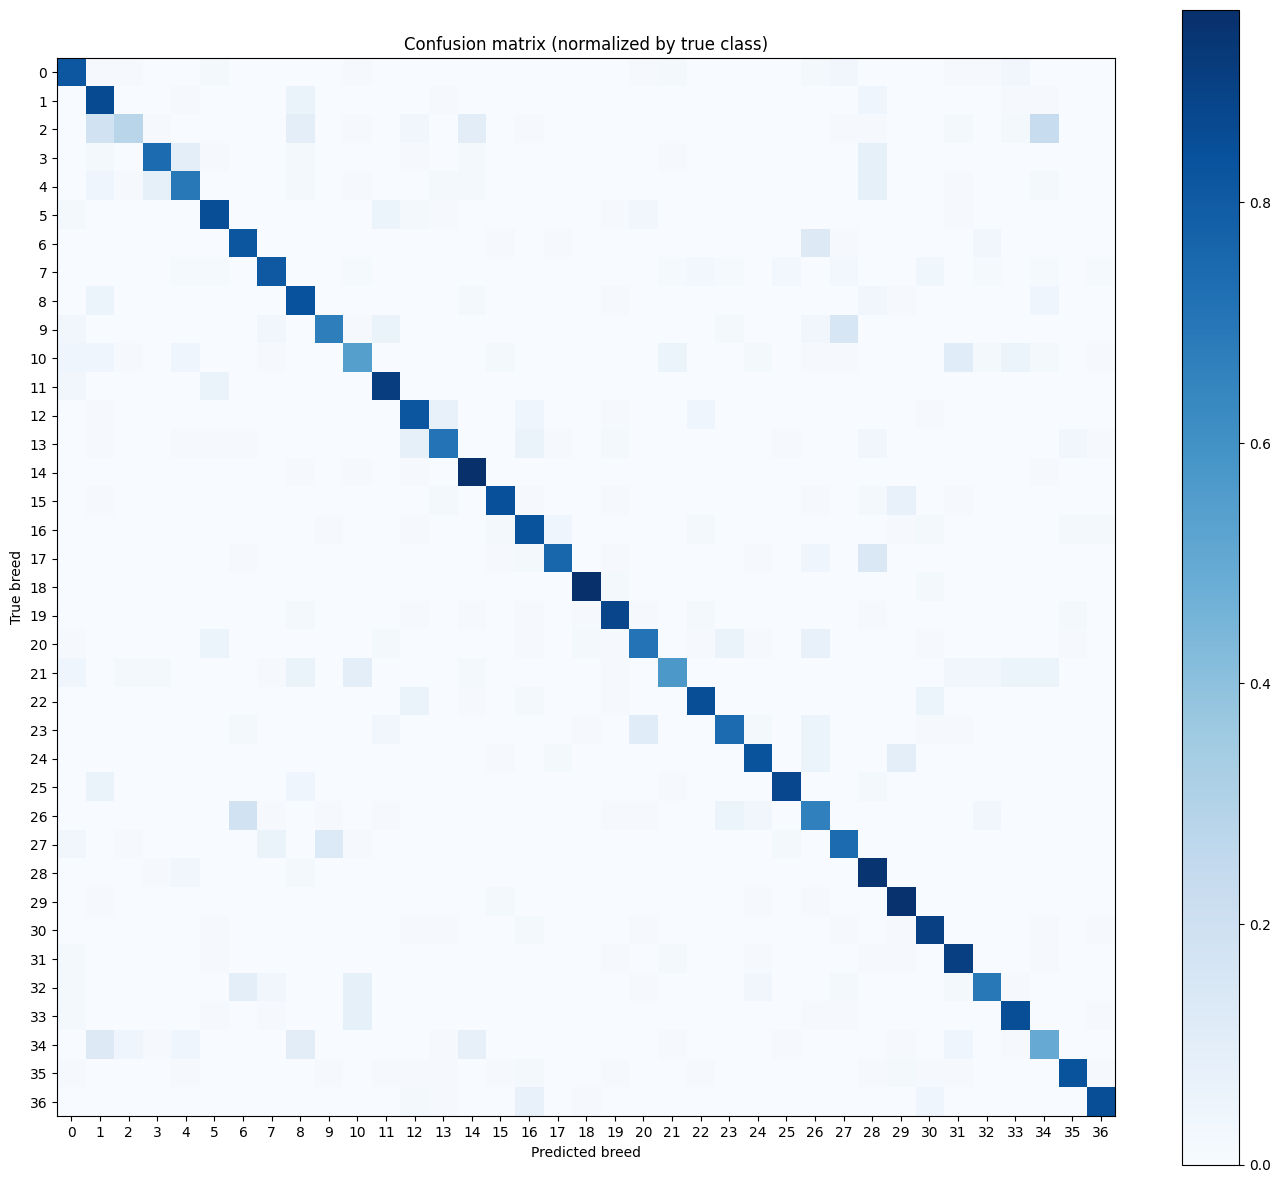

In [26]:

train_test_net(model_ft, train_loader, eval_loader, test_loader, nn.CrossEntropyLoss(label_smoothing=0.1), torch.optim.Adam(model_ft.parameters(), lr=2e-5))   #1e-3,1e-4, 3e-5 lead to overfitting (high t_acc, low loss and v_acc) and achieve wrost result than feature extractor


TRAIN OF ONLY THE FULLY CONNECTED LAYERS
other 3.0 epochs achieved!
train loss 0.092 train acc 0.997
val loss 0.526 val acc 0.848



other 3.0 epochs achieved!
train loss 0.064 train acc 0.996
val loss 0.515 val acc 0.845



other 3.0 epochs achieved!
train loss 0.045 train acc 0.996
val loss 0.513 val acc 0.844



other 3.0 epochs achieved!
train loss 0.038 train acc 0.999
val loss 0.506 val acc 0.849



best head training epoch for accuracy: 1



TEST OF THE ONLY CONVOLUTIONAL LAYER TRAINING
Test Set Accuracy: 78.99%
Test Set Macro F1 score: 0.79


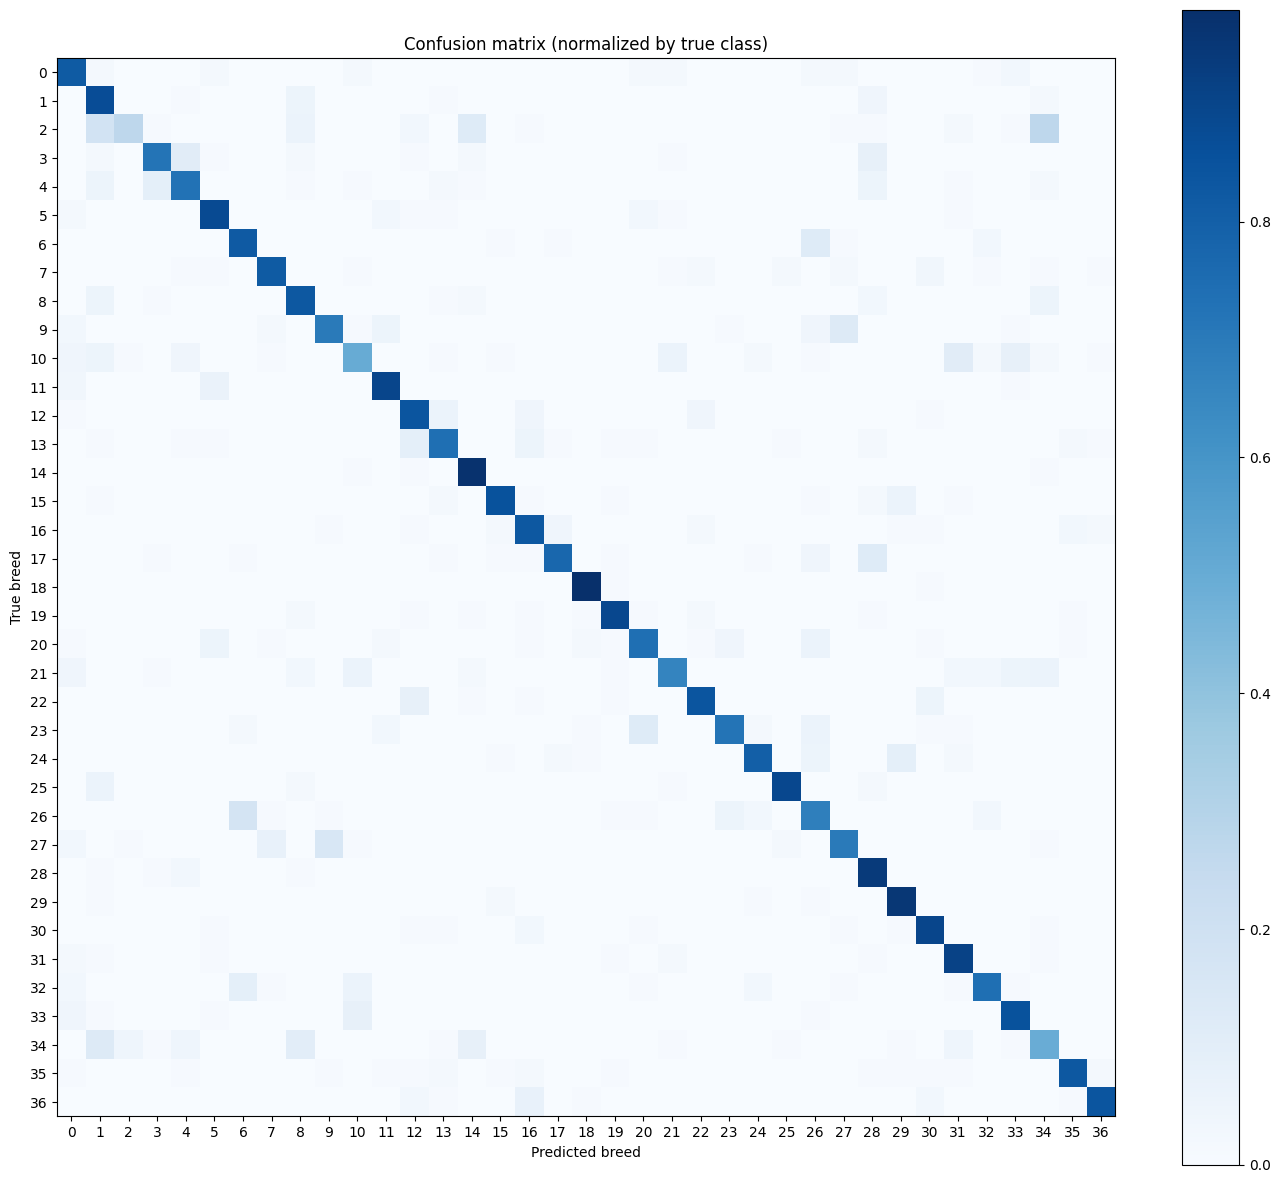

In [27]:
train_test_oc(model_ft, train_loader, eval_loader, test_loader, nn.CrossEntropyLoss())


n_estimators=100 max_depth=None val acc 0.8057
n_estimators=100 max_depth=20 val acc 0.8193
n_estimators=300 max_depth=None val acc 0.8315
n_estimators=300 max_depth=20 val acc 0.8315
n_estimators=500 max_depth=None val acc 0.8315
n_estimators=500 max_depth=20 val acc 0.8370
test acc 0.7986 | macro F1 0.7924


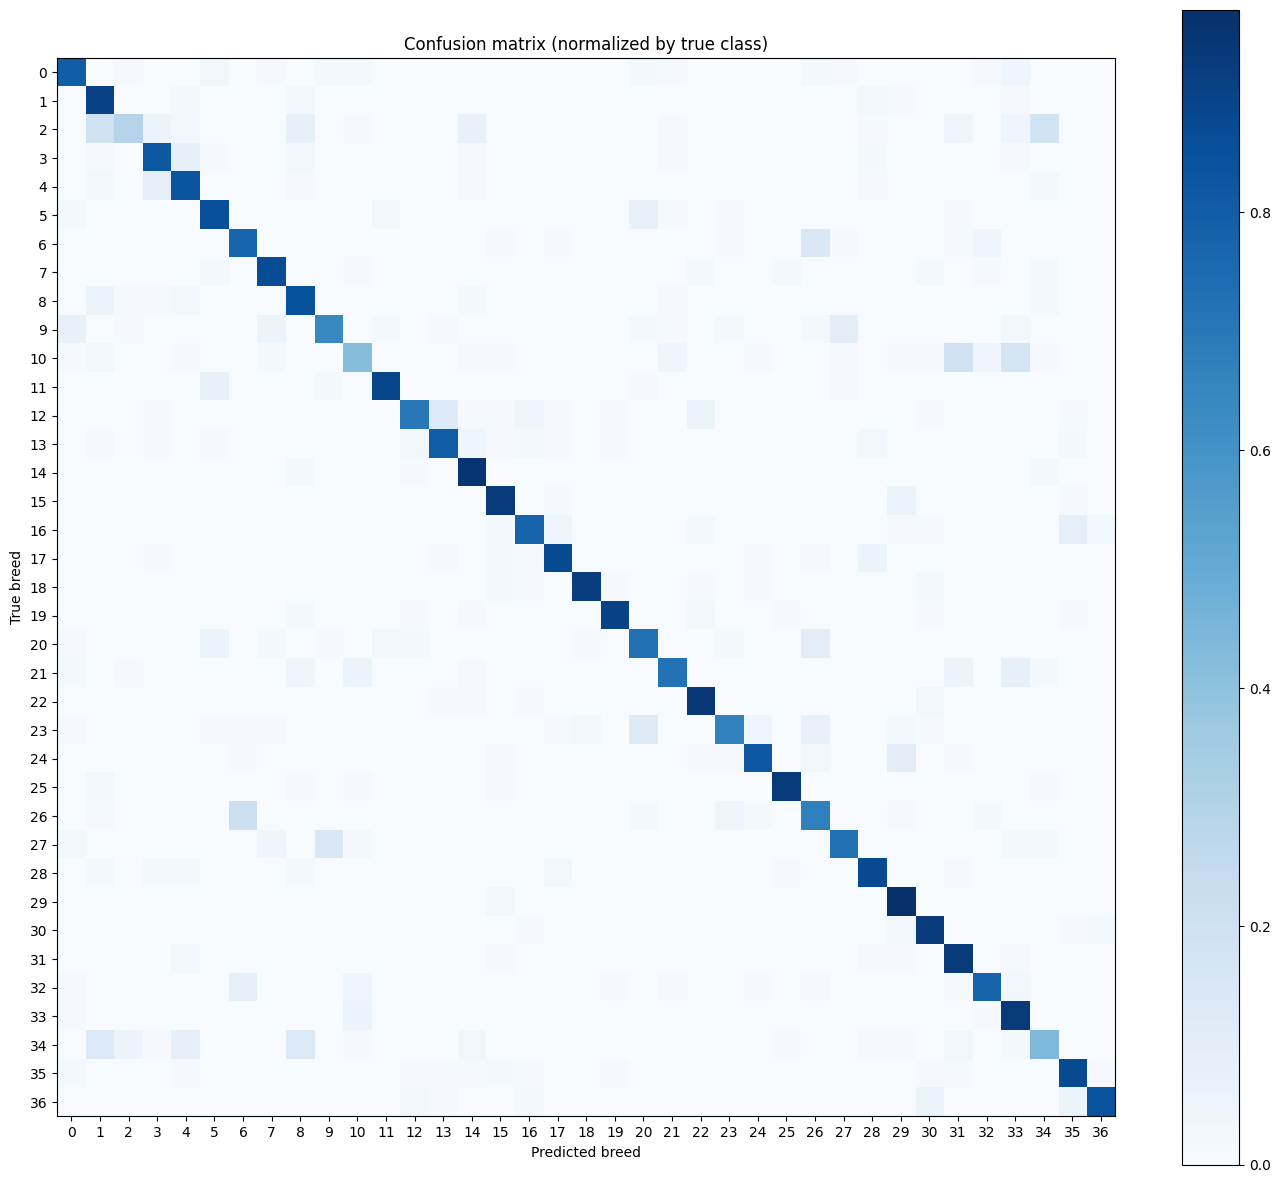

In [28]:
feat_extr_tc(prenet, ds_train, ds_eval, test_ds)